# MLP na datasete Communities and Crime (Zadanie 2)

Tento notebook nadväzuje na Malé zadanie č.1 (dataset **Communities and Crime**)  
a skúma použitie **MLPRegressor** pri rôznych train/test splitoch a porovnáva ho
s baseline modelom **RandomForestRegressor** z prvého zadania.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print(f"Random state: {RANDOM_STATE}")

Random state: 42


## 2. Načítanie a základné spracovanie datasetu

Dataset: **Communities and Crime** z UCI ML Repository (ID = 183).  
Cieľová premenná: `ViolentCrimesPerPop` (regresia, normalizovaná na [0,1]).

Kroky:
1. Načítanie dát cez `ucimlrepo`.
2. Náhrada symbolu `'?'` za `NaN` a konverzia na číselné typy.
3. Odstránenie riadkov s chýbajúcou hodnotou v cieli.
4. Odstránenie stĺpcov s 100% chýbajúcimi hodnotami.

In [2]:
def load_raw_communities_and_crime():
    print("Loading Communities and Crime dataset from UCI Repository ...")
    communities_crime = fetch_ucirepo(id=183)
    
    # Features a target
    X = communities_crime.data.features.copy()
    y = communities_crime.data.targets.copy()
    
    print("Original shapes:")
    print("  Features:", X.shape)
    print("  Target:  ", y.shape)
    
    # Nahradiť '?' -> NaN a skonvertovať na číselný typ
    questionmarks = 0
    for col in X.columns:
        if X[col].dtype == object:
            qm_count = (X[col] == "?").sum()
            questionmarks += qm_count
            if qm_count > 0:
                X[col] = X[col].replace("?", np.nan)
            X[col] = pd.to_numeric(X[col], errors="coerce")
    
    for col in y.columns:
        if y[col].dtype == object:
            y[col] = y[col].replace("?", np.nan)
            y[col] = pd.to_numeric(y[col], errors="coerce")
    
    print(f"Replaced {questionmarks} '?' symbols with NaN")
    
    # Odstrániť riadky s NaN v targete
    y_nan_count = y.isnull().sum().sum()
    if y_nan_count > 0:
        valid_idx = y.dropna().index
        X = X.loc[valid_idx]
        y = y.loc[valid_idx]
        print(f"Removed {y_nan_count} rows with NaN in target")
    
    # Odstrániť stĺpce, kde sú všetky hodnoty NaN
    null_counts = X.isnull().sum()
    fully_null_cols = null_counts[null_counts == len(X)].index
    if len(fully_null_cols) > 0:
        print(f"Removing {len(fully_null_cols)} columns with 100% NaN")
        X = X.drop(columns=fully_null_cols)
    
    print("\nFinal dataset info:")
    print(f"  Samples:  {X.shape[0]}")
    print(f"  Features: {X.shape[1]}")
    print(f"  Missing values in X: {X.isnull().sum().sum()}")
    print(f"  Missing values in y: {y.isnull().sum().sum()}")
    
    return X, y
X_raw, y_raw = load_raw_communities_and_crime()

Loading Communities and Crime dataset from UCI Repository ...
Original shapes:
  Features: (1994, 127)
  Target:   (1994, 1)
Replaced 39202 '?' symbols with NaN
Removing 1 columns with 100% NaN

Final dataset info:
  Samples:  1994
  Features: 126
  Missing values in X: 39202
  Missing values in y: 0


## 3. Pomocné funkcie: predspracovanie, trénovanie a hodnotenie

Budeme používať:
- **Imputáciu** chýbajúcich hodnôt (median).
- **Škálovanie** vstupov pomocou `StandardScaler`.
- Funkciu na trénovanie MLP po epochách a sledovanie `train`/`val` MSE.
- Funkciu na vyhodnotenie modelu na testovacej množine.

In [3]:
def preprocess_features(X_train, X_val, X_test):
    """
    Fitne SimpleImputer (median) a StandardScaler na X_train
    a aplikuje transformácie na X_train, X_val, X_test.
    Vracia transformované matice + objekty imputer a scaler.
    """
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    
    # Imputácia
    X_train_imp = imputer.fit_transform(X_train)
    X_val_imp   = imputer.transform(X_val)
    X_test_imp  = imputer.transform(X_test)
    
    # Škálovanie
    X_train_scaled = scaler.fit_transform(X_train_imp)
    X_val_scaled   = scaler.transform(X_val_imp)
    X_test_scaled  = scaler.transform(X_test_imp)
    
    return X_train_scaled, X_val_scaled, X_test_scaled, imputer, scaler

In [4]:
def create_mlp_model(random_state=RANDOM_STATE):
    """
    Vytvorí MLPRegressor s fixnou architektúrou,
    ktorá bude použitá pre všetky experimenty.
    """
    mlp = MLPRegressor(
        hidden_layer_sizes=(128, 64),  # aspoň 1 skrytá vrstva (tu 2)
        activation='relu',
        solver='adam',
        alpha=1e-3,
        batch_size=64,
        learning_rate_init=1e-3,
        max_iter=1,
        warm_start=True,
        early_stopping=False,
        random_state=random_state
    )
    return mlp


def train_mlp_with_validation(
    mlp,
    X_train,
    y_train,
    X_val,
    y_val,
    n_epochs=100,
    verbose=False
):
    y_train = np.asarray(y_train).ravel()
    y_val   = np.asarray(y_val).ravel()
    
    train_losses = []
    val_losses   = []
    
    for epoch in range(1, n_epochs + 1):
        mlp.fit(X_train, y_train)
        
        y_train_pred = mlp.predict(X_train)
        y_val_pred   = mlp.predict(X_val)
        
        train_loss = mean_squared_error(y_train, y_train_pred)
        val_loss   = mean_squared_error(y_val, y_val_pred)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        if verbose and (epoch % 10 == 0 or epoch == 1 or epoch == n_epochs):
            print(
                f"Epoch {epoch:3d} | "
                f"Train MSE: {train_loss:.4f} | "
                f"Val MSE: {val_loss:.4f}"
            )
    return mlp, train_losses, val_losses

In [5]:
def evaluate_on_test(model, X_test, y_test):
    y_test = np.asarray(y_test).ravel()
    y_pred = model.predict(X_test)
    
    r2  = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    
    return r2, rmse, mae, mse

In [6]:
def plot_learning_curves(train_losses, val_losses, title="MLP Learning Curves"):
    epochs = np.arange(1, len(train_losses) + 1)
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label="Train MSE", color="tab:blue")
    plt.plot(epochs, val_losses, label="Validation MSE", color="tab:orange")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Experimenty pre rôzne train/test splity

Splity:
- 50/50
- 60/40
- 70/30
- 80/20

Pre každý split:
1. Rozdelíme dáta na train_full a test.
2. Z train_full vyčleníme 20% ako validačnú množinu.
3. Imputujeme a škálujeme pomocou `preprocess_features`.
4. Trénujeme MLP cez `train_mlp_with_validation`.
5. Vyhodnotíme na testovacej množine.
6. Uložíme metriky a zobrazíme krivky učenia.

In [7]:
def run_mlp_experiment_for_split(
    X,
    y,
    train_fraction=0.7,
    n_epochs=100,
    random_state=RANDOM_STATE,
    verbose=False
):

    test_fraction = 1.0 - train_fraction
    assert 0.0 < test_fraction < 1.0, "Invalid train/test split."
    
    # 1) Train/test split
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X,
        y,
        test_size=test_fraction,
        random_state=random_state
    )
    
    # 2) Z train_full vyčleníme validačnú množinu (20 %)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full,
        y_train_full,
        test_size=0.2,
        random_state=random_state
    )
    
    # 3) Predspracovanie
    X_train_s, X_val_s, X_test_s, imputer, scaler = preprocess_features(
        X_train, X_val, X_test
    )
    
    # 4) Tréning MLP
    mlp = create_mlp_model(random_state=random_state)
    mlp, train_losses, val_losses = train_mlp_with_validation(
        mlp,
        X_train_s,
        y_train,
        X_val_s,
        y_val,
        n_epochs=n_epochs,
        verbose=verbose
    )
    
    # 5) Hodnotenie na test množine
    r2, rmse, mae, mse = evaluate_on_test(mlp, X_test_s, y_test)
    
    results = {
        "train_fraction": train_fraction,
        "test_fraction": test_fraction,
        "n_train": len(X_train),
        "n_val": len(X_val),
        "n_test": len(X_test),
        "r2": r2,
        "rmse": rmse,
        "mae": mae,
        "mse": mse,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "model": mlp,
    }
    
    return results

Running MLP experiment for train_fraction = 0.50 ...
Epoch   1 | Train MSE: 0.1466 | Val MSE: 0.1180
Epoch  10 | Train MSE: 0.0350 | Val MSE: 0.0531
Epoch  20 | Train MSE: 0.0301 | Val MSE: 0.0486
Epoch  30 | Train MSE: 0.0165 | Val MSE: 0.0317
Epoch  40 | Train MSE: 0.0204 | Val MSE: 0.0441
Epoch  50 | Train MSE: 0.0151 | Val MSE: 0.0368
Epoch  60 | Train MSE: 0.0117 | Val MSE: 0.0332
Epoch  70 | Train MSE: 0.0041 | Val MSE: 0.0260
Epoch  80 | Train MSE: 0.0130 | Val MSE: 0.0289
Epoch  90 | Train MSE: 0.0034 | Val MSE: 0.0236
Epoch 100 | Train MSE: 0.0092 | Val MSE: 0.0301

Split 0.50/0.50 | Train: 797, Val: 200, Test: 997
Test metrics: R2=0.2469, RMSE=0.2015, MAE=0.1566, MSE=0.0406


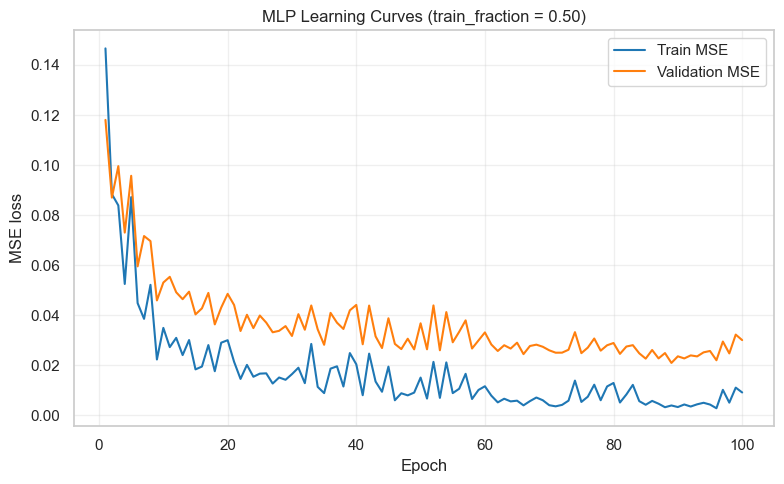

Running MLP experiment for train_fraction = 0.60 ...
Epoch   1 | Train MSE: 0.1095 | Val MSE: 0.1376
Epoch  10 | Train MSE: 0.0362 | Val MSE: 0.0682
Epoch  20 | Train MSE: 0.0127 | Val MSE: 0.0370
Epoch  30 | Train MSE: 0.0181 | Val MSE: 0.0439
Epoch  40 | Train MSE: 0.0082 | Val MSE: 0.0357
Epoch  50 | Train MSE: 0.0050 | Val MSE: 0.0293
Epoch  60 | Train MSE: 0.0068 | Val MSE: 0.0288
Epoch  70 | Train MSE: 0.0052 | Val MSE: 0.0321
Epoch  80 | Train MSE: 0.0041 | Val MSE: 0.0260
Epoch  90 | Train MSE: 0.0023 | Val MSE: 0.0251
Epoch 100 | Train MSE: 0.0031 | Val MSE: 0.0232

Split 0.60/0.40 | Train: 956, Val: 240, Test: 798
Test metrics: R2=0.5089, RMSE=0.1562, MAE=0.1121, MSE=0.0244


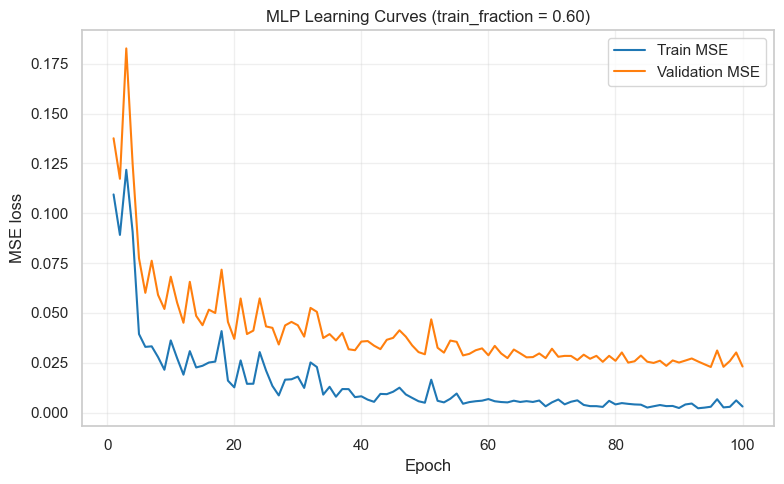

Running MLP experiment for train_fraction = 0.70 ...
Epoch   1 | Train MSE: 0.0963 | Val MSE: 0.1322
Epoch  10 | Train MSE: 0.0218 | Val MSE: 0.0482
Epoch  20 | Train MSE: 0.0280 | Val MSE: 0.0423
Epoch  30 | Train MSE: 0.0142 | Val MSE: 0.0334
Epoch  40 | Train MSE: 0.0070 | Val MSE: 0.0246
Epoch  50 | Train MSE: 0.0112 | Val MSE: 0.0329
Epoch  60 | Train MSE: 0.0050 | Val MSE: 0.0280
Epoch  70 | Train MSE: 0.0050 | Val MSE: 0.0236
Epoch  80 | Train MSE: 0.0024 | Val MSE: 0.0238
Epoch  90 | Train MSE: 0.0023 | Val MSE: 0.0241
Epoch 100 | Train MSE: 0.0015 | Val MSE: 0.0222

Split 0.70/0.30 | Train: 1116, Val: 279, Test: 599
Test metrics: R2=0.5012, RMSE=0.1545, MAE=0.1096, MSE=0.0239


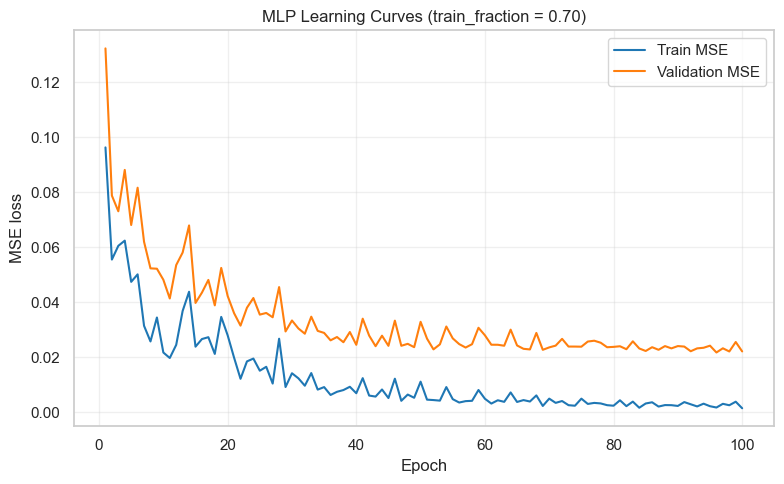

Running MLP experiment for train_fraction = 0.80 ...
Epoch   1 | Train MSE: 0.0706 | Val MSE: 0.0858
Epoch  10 | Train MSE: 0.0155 | Val MSE: 0.0383
Epoch  20 | Train MSE: 0.0217 | Val MSE: 0.0439
Epoch  30 | Train MSE: 0.0109 | Val MSE: 0.0316
Epoch  40 | Train MSE: 0.0081 | Val MSE: 0.0295
Epoch  50 | Train MSE: 0.0041 | Val MSE: 0.0272
Epoch  60 | Train MSE: 0.0130 | Val MSE: 0.0378
Epoch  70 | Train MSE: 0.0040 | Val MSE: 0.0251
Epoch  80 | Train MSE: 0.0034 | Val MSE: 0.0271
Epoch  90 | Train MSE: 0.0080 | Val MSE: 0.0310
Epoch 100 | Train MSE: 0.0072 | Val MSE: 0.0311

Split 0.80/0.20 | Train: 1276, Val: 319, Test: 399
Test metrics: R2=0.4353, RMSE=0.1645, MAE=0.1130, MSE=0.0270


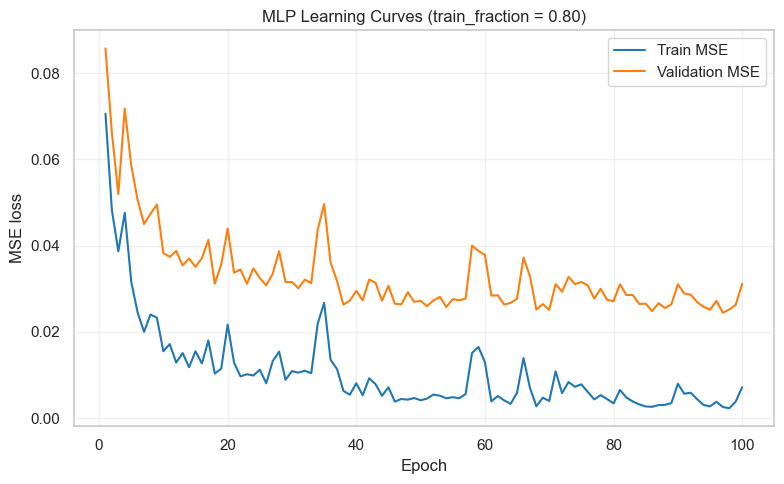

In [8]:
# Spustenie všetkých splitov a vizualizácia

splits = [0.5, 0.6, 0.7, 0.8]
N_EPOCHS = 100

all_results = []

for frac in splits:
    print("=" * 60)
    print(f"Running MLP experiment for train_fraction = {frac:.2f} ...")
    res = run_mlp_experiment_for_split(
        X_raw,
        y_raw,
        train_fraction=frac,
        n_epochs=N_EPOCHS,
        random_state=RANDOM_STATE,
        verbose=True
    )
    all_results.append(res)
    
    print(
        f"\nSplit {frac:.2f}/{1-frac:.2f} | "
        f"Train: {res['n_train']}, Val: {res['n_val']}, Test: {res['n_test']}"
    )
    print(
        f"Test metrics: R2={res['r2']:.4f}, "
        f"RMSE={res['rmse']:.4f}, MAE={res['mae']:.4f}, MSE={res['mse']:.4f}"
    )
    
    title = f"MLP Learning Curves (train_fraction = {frac:.2f})"
    plot_learning_curves(res["train_losses"], res["val_losses"], title=title)

In [9]:
summary_rows = []
for res in all_results:
    summary_rows.append({
        "Train fraction": res["train_fraction"],
        "Test fraction":  res["test_fraction"],
        "N_train": res["n_train"],
        "N_val":   res["n_val"],
        "N_test":  res["n_test"],
        "R2":      res["r2"],
        "RMSE":    res["rmse"],
        "MAE":     res["mae"],
        "MSE":     res["mse"],
    })

results_df = pd.DataFrame(summary_rows)
results_df = results_df.sort_values("Train fraction").reset_index(drop=True)

print("MLP results for different train/test splits:")
display(results_df.style.format({
    "R2": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}",
    "MSE": "{:.4f}",
}))

MLP results for different train/test splits:


,Train fraction,Test fraction,N_train,N_val,N_test,R2,RMSE,MAE,MSE
0,0.500000,0.500000,797,200,997,0.2469,0.2015,0.1566,0.0406
1,0.600000,0.400000,956,240,798,0.5089,0.1562,0.1121,0.0244
2,0.700000,0.300000,1116,279,599,0.5012,0.1545,0.1096,0.0239
3,0.800000,0.200000,1276,319,399,0.4353,0.1645,0.1130,0.0270


## 5. Baseline: RandomForestRegressor vs. MLP (split 70/30)

Ako baseline berieme **RandomForestRegressor** z Malého zadania č.1.
Aby bolo porovnanie korektné:

- použijeme rovnaký **train/test split 70/30** (`random_state=42`),
- rovnaký predspracovací pipeline (imputácia + škálovanie),
- potom vyhodnotíme RF aj MLP na TOM ISTOM `X_test`, `y_test`.

In [10]:
def run_random_forest_baseline(
    X,
    y,
    train_fraction=0.7,
    random_state=RANDOM_STATE
):
    test_fraction = 1.0 - train_fraction
    
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X,
        y,
        test_size=test_fraction,
        random_state=random_state
    )
    
    X_train_s, X_val_s, X_test_s, imputer, scaler = preprocess_features(
        X_train_full, X_train_full, X_test
    )
    
    y_train_full = np.asarray(y_train_full).ravel()
    
    # Hyperparametre z Malého zadania č.1
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=random_state,
        n_jobs=-1
    )
    
    rf.fit(X_train_s, y_train_full)
    r2, rmse, mae, mse = evaluate_on_test(rf, X_test_s, y_test)
    
    return {
        "model": rf,
        "r2": r2,
        "rmse": rmse,
        "mae": mae,
        "mse": mse,
        "n_train": len(X_train_full),
        "n_test": len(X_test),
    }

print("Running RandomForest baseline for train_fraction=0.70 ...")
rf_baseline_res = run_random_forest_baseline(X_raw, y_raw, train_fraction=0.7)
print(
    f"RF baseline (70/30): R2={rf_baseline_res['r2']:.4f}, "
    f"RMSE={rf_baseline_res['rmse']:.4f}, "
    f"MAE={rf_baseline_res['mae']:.4f}, "
    f"MSE={rf_baseline_res['mse']:.4f}"
)

Running RandomForest baseline for train_fraction=0.70 ...
RF baseline (70/30): R2=0.6351, RMSE=0.1322, MAE=0.0926, MSE=0.0175


In [11]:
mlp_70_result = None
for res in all_results:
    if abs(res["train_fraction"] - 0.7) < 1e-6:
        mlp_70_result = res
        break

if mlp_70_result is None:
    raise ValueError("MLP result for train_fraction=0.7 not found.")

comparison_df = pd.DataFrame([
    {
        "Model": "RandomForest (baseline)",
        "Train fraction": 0.7,
        "Test fraction":  0.3,
        "R2":   rf_baseline_res["r2"],
        "RMSE": rf_baseline_res["rmse"],
        "MAE":  rf_baseline_res["mae"],
        "MSE":  rf_baseline_res["mse"],
    },
    {
        "Model": "MLPRegressor",
        "Train fraction": mlp_70_result["train_fraction"],
        "Test fraction":  mlp_70_result["test_fraction"],
        "R2":   mlp_70_result["r2"],
        "RMSE": mlp_70_result["rmse"],
        "MAE":  mlp_70_result["mae"],
        "MSE":  mlp_70_result["mse"],
    }
])

print("Baseline vs. MLP (split 70/30):")
display(comparison_df.style.format({
    "R2": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}",
    "MSE": "{:.4f}",
}))

Baseline vs. MLP (split 70/30):


,Model,Train fraction,Test fraction,R2,RMSE,MAE,MSE
0,RandomForest (baseline),0.700000,0.300000,0.6351,0.1322,0.0926,0.0175
1,MLPRegressor,0.700000,0.300000,0.5012,0.1545,0.1096,0.0239
